# Direction du vent — notebook propre

On charge le dataset final du groupe et on vérifie que les variables de direction du vent sont bien présentes avant de commencer les tests.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

In [2]:
df = pd.read_csv("../data/weatherAUS.csv")
print(df.shape)
print(df.dtypes[["WindGustDir", "WindDir9am", "WindDir3pm", "RainToday", "RainTomorrow"]])

(145460, 23)
WindGustDir     str
WindDir9am      str
WindDir3pm      str
RainToday       str
RainTomorrow    str
dtype: object


On regarde les modalités exactes des directions du vent et le nombre de valeurs manquantes pour préparer correctement leur encodage.

In [3]:
wind_dir_cols = ["WindGustDir", "WindDir9am", "WindDir3pm"]

for col in wind_dir_cols:
    print(f"\n--- {col} ---")
    print("NaN :", df[col].isna().sum())
    print("Valeurs uniques :")
    print(sorted(df[col].dropna().unique()))


--- WindGustDir ---
NaN : 10326
Valeurs uniques :
['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']

--- WindDir9am ---
NaN : 10566
Valeurs uniques :
['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']

--- WindDir3pm ---
NaN : 4228
Valeurs uniques :
['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']


On prépare le dataset de modélisation, on convertit la date, on crée la cible binaire et on fixe les variables de base qui serviront aux baselines.

In [4]:
df_model = df.copy()
df_model["Date"] = pd.to_datetime(df_model["Date"])
df_model = df_model.sort_values("Date").reset_index(drop=True)
df_model["RainTomorrow_num"] = df_model["RainTomorrow"].astype(int)

base_features = [
    "MinTemp", "MaxTemp", "Rainfall",
    "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm",
    "Humidity9am", "Humidity3pm",
    "Pressure9am", "Pressure3pm",
    "Cloud9am", "Cloud3pm",
    "Temp9am", "Temp3pm"
]

wind_cat_features = ["WindGustDir", "WindDir9am", "WindDir3pm"]

print(df_model.shape)
print(df_model[["Date", "RainTomorrow", "RainTomorrow_num"]].head())

ValueError: invalid literal for int() with base 10: 'Yes'

On découpe les données avec un split temporel pour respecter l’ordre chronologique entre apprentissage et test.

In [12]:
split_index = int(len(df_model) * 0.8)

train_df = df_model.iloc[:split_index].copy()
test_df = df_model.iloc[split_index:].copy()

print("Train shape :", train_df.shape)
print("Test shape :", test_df.shape)
print("Train period :", train_df["Date"].min(), "->", train_df["Date"].max())
print("Test period  :", test_df["Date"].min(), "->", test_df["Date"].max())

Train shape : (111056, 33)
Test shape : (27764, 33)
Train period : 2007-11-01 00:00:00 -> 2015-11-09 00:00:00
Test period  : 2015-11-09 00:00:00 -> 2017-06-25 00:00:00


On entraîne une première régression logistique sans aucune direction du vent pour obtenir une baseline de référence.

In [13]:
X_train = train_df[base_features]
y_train = train_df["RainTomorrow_num"]

X_test = test_df[base_features]
y_test = test_df["RainTomorrow_num"]

baseline_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

baseline_pipe.fit(X_train, y_train)

y_pred = baseline_pipe.predict(X_test)
y_proba = baseline_pipe.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("F1 score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_proba))
print("\nClassification report :\n")
print(classification_report(y_test, y_pred))

Accuracy : 0.7819478461316813
F1 score : 0.6112252761366556
ROC AUC  : 0.8600553387417286

Classification report :

              precision    recall  f1-score   support

           0       0.92      0.78      0.85     21624
           1       0.50      0.78      0.61      6140

    accuracy                           0.78     27764
   macro avg       0.71      0.78      0.73     27764
weighted avg       0.83      0.78      0.80     27764



On ajoute ensuite les trois directions du vent encodées en one-hot pour mesurer leur apport direct au modèle.

In [14]:
X_train_oh = train_df[base_features + wind_cat_features]
y_train_oh = train_df["RainTomorrow_num"]

X_test_oh = test_df[base_features + wind_cat_features]
y_test_oh = test_df["RainTomorrow_num"]

preprocessor_oh = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), base_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), wind_cat_features)
])

logreg_oh_pipe = Pipeline([
    ("preprocessor", preprocessor_oh),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

logreg_oh_pipe.fit(X_train_oh, y_train_oh)

y_pred_oh = logreg_oh_pipe.predict(X_test_oh)
y_proba_oh = logreg_oh_pipe.predict_proba(X_test_oh)[:, 1]

print("Accuracy :", accuracy_score(y_test_oh, y_pred_oh))
print("F1 score :", f1_score(y_test_oh, y_pred_oh))
print("ROC AUC  :", roc_auc_score(y_test_oh, y_proba_oh))
print("\nClassification report :\n")
print(classification_report(y_test_oh, y_pred_oh))

Accuracy : 0.783496614320703
F1 score : 0.6145559474190445
ROC AUC  : 0.86218031509205

Classification report :

              precision    recall  f1-score   support

           0       0.93      0.78      0.85     21624
           1       0.51      0.78      0.61      6140

    accuracy                           0.78     27764
   macro avg       0.72      0.78      0.73     27764
weighted avg       0.83      0.78      0.80     27764



On convertit les directions du vent en angles puis en sinus et cosinus pour tester un encodage circulaire plus fidèle à la nature directionnelle du vent.

In [15]:
wind_dir_map = {
    "N": 0.0, "NNE": 22.5, "NE": 45.0, "ENE": 67.5,
    "E": 90.0, "ESE": 112.5, "SE": 135.0, "SSE": 157.5,
    "S": 180.0, "SSW": 202.5, "SW": 225.0, "WSW": 247.5,
    "W": 270.0, "WNW": 292.5, "NW": 315.0, "NNW": 337.5
}

for col in wind_cat_features:
    angle_col = f"{col}_angle"
    sin_col = f"{col}_sin"
    cos_col = f"{col}_cos"
    df_model[angle_col] = df_model[col].map(wind_dir_map)
    radians = np.deg2rad(df_model[angle_col])
    df_model[sin_col] = np.sin(radians)
    df_model[cos_col] = np.cos(radians)

df_model[[
    "WindGustDir", "WindGustDir_angle", "WindGustDir_sin", "WindGustDir_cos",
    "WindDir9am", "WindDir9am_angle", "WindDir9am_sin", "WindDir9am_cos",
    "WindDir3pm", "WindDir3pm_angle", "WindDir3pm_sin", "WindDir3pm_cos"
]].head()

,WindGustDir,WindGustDir_angle,WindGustDir_sin,WindGustDir_cos,WindDir9am,WindDir9am_angle,WindDir9am_sin,WindDir9am_cos,WindDir3pm,WindDir3pm_angle,WindDir3pm_sin,WindDir3pm_cos
0,NW,315.0,-0.707107,0.707107,SW,225.0,-0.707107,-7.071068e-01,NW,315.0,-0.707107,7.071068e-01
1,ENE,67.5,0.923880,0.382683,E,90.0,1.000000,6.123234e-17,W,270.0,-1.000000,-1.836970e-16
2,NW,315.0,-0.707107,0.707107,N,0.0,0.000000,1.000000e+00,NNE,22.5,0.382683,9.238795e-01
3,NW,315.0,-0.707107,0.707107,WNW,292.5,-0.923880,3.826834e-01,W,270.0,-1.000000,-1.836970e-16
4,SSE,157.5,0.382683,-0.923880,SSE,157.5,0.382683,-9.238795e-01,ESE,112.5,0.923880,-3.826834e-01


On teste la régression logistique avec l’encodage circulaire du vent pour comparer cette approche à l’encodage one-hot.

In [16]:
wind_cyc_features = [
    "WindGustDir_sin", "WindGustDir_cos",
    "WindDir9am_sin", "WindDir9am_cos",
    "WindDir3pm_sin", "WindDir3pm_cos"
]

train_df = df_model.iloc[:split_index].copy()
test_df = df_model.iloc[split_index:].copy()

X_train_cyc = train_df[base_features + wind_cyc_features]
y_train_cyc = train_df["RainTomorrow_num"]

X_test_cyc = test_df[base_features + wind_cyc_features]
y_test_cyc = test_df["RainTomorrow_num"]

cyc_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

cyc_pipe.fit(X_train_cyc, y_train_cyc)

y_pred_cyc = cyc_pipe.predict(X_test_cyc)
y_proba_cyc = cyc_pipe.predict_proba(X_test_cyc)[:, 1]

print("Accuracy :", accuracy_score(y_test_cyc, y_pred_cyc))
print("F1 score :", f1_score(y_test_cyc, y_pred_cyc))
print("ROC AUC  :", roc_auc_score(y_test_cyc, y_proba_cyc))
print("\nClassification report :\n")
print(classification_report(y_test_cyc, y_pred_cyc))

Accuracy : 0.7818037746722374
F1 score : 0.6123624264141285
ROC AUC  : 0.861180212359051

Classification report :

              precision    recall  f1-score   support

           0       0.93      0.78      0.85     21624
           1       0.50      0.78      0.61      6140

    accuracy                           0.78     27764
   macro avg       0.72      0.78      0.73     27764
weighted avg       0.83      0.78      0.80     27764



On rassemble les résultats des trois versions logistiques pour comparer directement l’effet de la direction du vent et de son encodage.

In [17]:
results_wind = pd.DataFrame({
    "version": [
        "Sans direction du vent",
        "Direction du vent en one-hot",
        "Direction du vent en sin/cos"
    ],
    "accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test_oh, y_pred_oh),
        accuracy_score(y_test_cyc, y_pred_cyc)
    ],
    "f1_score": [
        f1_score(y_test, y_pred),
        f1_score(y_test_oh, y_pred_oh),
        f1_score(y_test_cyc, y_pred_cyc)
    ],
    "roc_auc": [
        roc_auc_score(y_test, y_proba),
        roc_auc_score(y_test_oh, y_proba_oh),
        roc_auc_score(y_test_cyc, y_proba_cyc)
    ]
})

results_wind

,version,accuracy,f1_score,roc_auc
0,Sans direction du vent,0.781948,0.611225,0.860055
1,Direction du vent en one-hot,0.783497,0.614556,0.862180
2,Direction du vent en sin/cos,0.781804,0.612362,0.861180


On teste maintenant un arbre de décision sans variables de direction du vent pour comparer l’apport du vent sur un second modèle simple.

In [18]:
tree_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=42, class_weight="balanced", max_depth=6))
])

tree_pipe.fit(X_train, y_train)

y_pred_tree = tree_pipe.predict(X_test)
y_proba_tree = tree_pipe.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_tree))
print("F1 score :", f1_score(y_test, y_pred_tree))
print("ROC AUC  :", roc_auc_score(y_test, y_proba_tree))
print("\nClassification report :\n")
print(classification_report(y_test, y_pred_tree))

Accuracy : 0.7801469528886328
F1 score : 0.5928495197438634
ROC AUC  : 0.8398279945313508

Classification report :

              precision    recall  f1-score   support

           0       0.91      0.80      0.85     21624
           1       0.50      0.72      0.59      6140

    accuracy                           0.78     27764
   macro avg       0.71      0.76      0.72     27764
weighted avg       0.82      0.78      0.79     27764



On ajoute la direction du vent encodée en one-hot à l’arbre de décision pour vérifier si son apport se retrouve sur un autre modèle.

In [19]:
tree_oh_pipe = Pipeline([
    ("preprocessor", preprocessor_oh),
    ("model", DecisionTreeClassifier(random_state=42, class_weight="balanced", max_depth=6))
])

tree_oh_pipe.fit(X_train_oh, y_train_oh)

y_pred_tree_oh = tree_oh_pipe.predict(X_test_oh)
y_proba_tree_oh = tree_oh_pipe.predict_proba(X_test_oh)[:, 1]

print("Accuracy :", accuracy_score(y_test_oh, y_pred_tree_oh))
print("F1 score :", f1_score(y_test_oh, y_pred_tree_oh))
print("ROC AUC  :", roc_auc_score(y_test_oh, y_proba_tree_oh))
print("\nClassification report :\n")
print(classification_report(y_test_oh, y_pred_tree_oh))

Accuracy : 0.7827762570234836
F1 score : 0.5952620629487954
ROC AUC  : 0.8399160067351874

Classification report :

              precision    recall  f1-score   support

           0       0.91      0.80      0.85     21624
           1       0.51      0.72      0.60      6140

    accuracy                           0.78     27764
   macro avg       0.71      0.76      0.72     27764
weighted avg       0.82      0.78      0.79     27764



On compare les performances de la logistique et de l’arbre, avec et sans direction du vent, pour voir si le signal du vent est robuste.

In [20]:
results_models = pd.DataFrame({
    "modele": [
        "Logistique - sans vent",
        "Logistique - vent one-hot",
        "Arbre - sans vent",
        "Arbre - vent one-hot"
    ],
    "accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test_oh, y_pred_oh),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test_oh, y_pred_tree_oh)
    ],
    "f1_score": [
        f1_score(y_test, y_pred),
        f1_score(y_test_oh, y_pred_oh),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test_oh, y_pred_tree_oh)
    ],
    "roc_auc": [
        roc_auc_score(y_test, y_proba),
        roc_auc_score(y_test_oh, y_proba_oh),
        roc_auc_score(y_test, y_proba_tree),
        roc_auc_score(y_test_oh, y_proba_tree_oh)
    ]
})

results_models

,modele,accuracy,f1_score,roc_auc
0,Logistique - sans vent,0.781948,0.611225,0.860055
1,Logistique - vent one-hot,0.783497,0.614556,0.862180
2,Arbre - sans vent,0.780147,0.592850,0.839828
3,Arbre - vent one-hot,0.782776,0.595262,0.839916


On construit des variables dérivées du vent pour résumer les changements de direction dans la journée et tester si la dynamique du vent améliore le modèle.

In [21]:
def angular_diff_deg(a1, a2):
    diff = np.abs(a1 - a2)
    return np.minimum(diff, 360 - diff)

df_model["WindDir_change_9am_3pm"] = angular_diff_deg(
    df_model["WindDir9am_angle"],
    df_model["WindDir3pm_angle"]
)

df_model["WindDir_change_3pm_gust"] = angular_diff_deg(
    df_model["WindDir3pm_angle"],
    df_model["WindGustDir_angle"]
)

df_model["WindDir_stable_9am_3pm"] = df_model["WindDir_change_9am_3pm"] <= 45
df_model["WindDir_aligned_3pm_gust"] = df_model["WindDir_change_3pm_gust"] <= 45

df_model[[
    "WindDir_change_9am_3pm",
    "WindDir_change_3pm_gust",
    "WindDir_stable_9am_3pm",
    "WindDir_aligned_3pm_gust"
]].head()

,WindDir_change_9am_3pm,WindDir_change_3pm_gust,WindDir_stable_9am_3pm,WindDir_aligned_3pm_gust
0,90.0,0.0,False,True
1,180.0,157.5,False,False
2,22.5,67.5,True,False
3,22.5,45.0,True,True
4,45.0,45.0,True,True


On teste si l’ajout de variables décrivant la stabilité et les variations du vent améliore le modèle par rapport à la version one-hot simple.

In [22]:
wind_extra_features = [
    "WindDir_change_9am_3pm",
    "WindDir_change_3pm_gust",
    "WindDir_stable_9am_3pm",
    "WindDir_aligned_3pm_gust"
]

train_df = df_model.iloc[:split_index].copy()
test_df = df_model.iloc[split_index:].copy()

X_train_oh_plus = train_df[base_features + wind_cat_features + wind_extra_features]
y_train_oh_plus = train_df["RainTomorrow_num"]

X_test_oh_plus = test_df[base_features + wind_cat_features + wind_extra_features]
y_test_oh_plus = test_df["RainTomorrow_num"]

preprocessor_oh_plus = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), base_features + wind_extra_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), wind_cat_features)
])

logreg_oh_plus_pipe = Pipeline([
    ("preprocessor", preprocessor_oh_plus),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

logreg_oh_plus_pipe.fit(X_train_oh_plus, y_train_oh_plus)

y_pred_oh_plus = logreg_oh_plus_pipe.predict(X_test_oh_plus)
y_proba_oh_plus = logreg_oh_plus_pipe.predict_proba(X_test_oh_plus)[:, 1]

print("Accuracy :", accuracy_score(y_test_oh_plus, y_pred_oh_plus))
print("F1 score :", f1_score(y_test_oh_plus, y_pred_oh_plus))
print("ROC AUC  :", roc_auc_score(y_test_oh_plus, y_proba_oh_plus))
print("\nClassification report :\n")
print(classification_report(y_test_oh_plus, y_pred_oh_plus))

Accuracy : 0.7828843106180665
F1 score : 0.6131930184804928
ROC AUC  : 0.862569864464746

Classification report :

              precision    recall  f1-score   support

           0       0.93      0.78      0.85     21624
           1       0.51      0.78      0.61      6140

    accuracy                           0.78     27764
   macro avg       0.72      0.78      0.73     27764
weighted avg       0.83      0.78      0.80     27764



On compare la version one-hot simple et la version enrichie pour mesurer l’apport réel des variables dérivées du vent.

In [23]:
results_wind_extended = pd.DataFrame({
    "version": [
        "Vent one-hot",
        "Vent one-hot + features dérivées"
    ],
    "accuracy": [
        accuracy_score(y_test_oh, y_pred_oh),
        accuracy_score(y_test_oh_plus, y_pred_oh_plus)
    ],
    "f1_score": [
        f1_score(y_test_oh, y_pred_oh),
        f1_score(y_test_oh_plus, y_pred_oh_plus)
    ],
    "roc_auc": [
        roc_auc_score(y_test_oh, y_proba_oh),
        roc_auc_score(y_test_oh_plus, y_proba_oh_plus)
    ]
})

results_wind_extended

,version,accuracy,f1_score,roc_auc
0,Vent one-hot,0.783497,0.614556,0.86218
1,Vent one-hot + features dérivées,0.782884,0.613193,0.86257


On génère une première figure pour visualiser l’effet des différents encodages du vent sur les métriques principales.

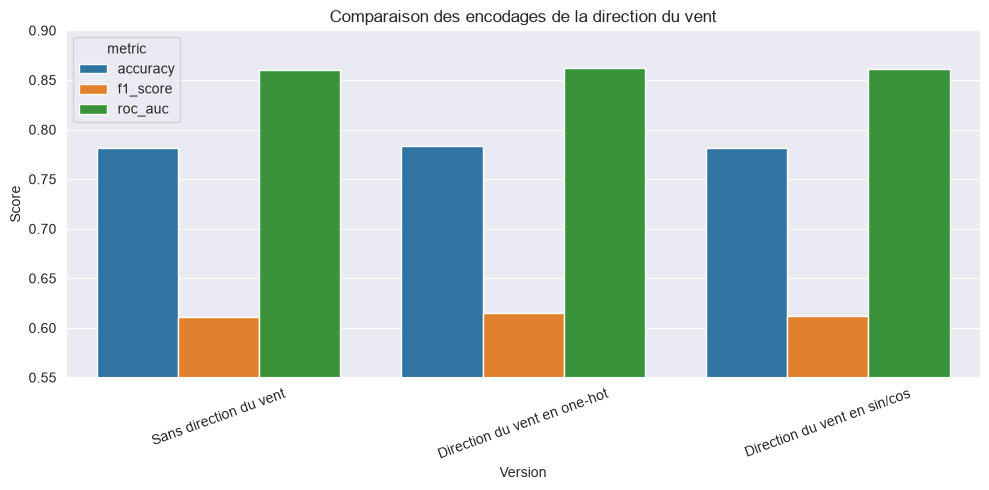

In [24]:
plot_df = results_wind.melt(id_vars="version", var_name="metric", value_name="score")

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_df, x="version", y="score", hue="metric")
plt.title("Comparaison des encodages de la direction du vent")
plt.xlabel("Version")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0.55, 0.90)
plt.tight_layout()
plt.savefig("figure_encodage_vent.png", dpi=300, bbox_inches="tight")
plt.show()

On génère une deuxième figure pour visualiser l’apport des variables dérivées du vent par rapport au one-hot simple.

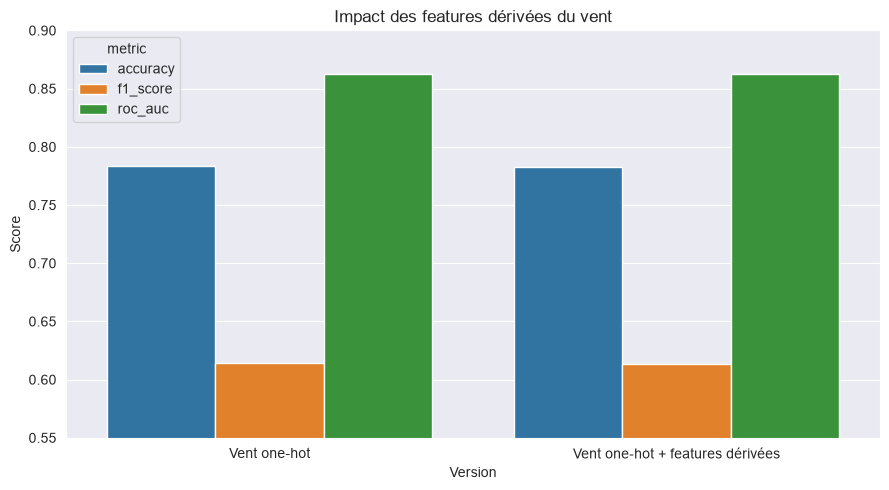

In [25]:
plot_df_ext = results_wind_extended.melt(id_vars="version", var_name="metric", value_name="score")

plt.figure(figsize=(9, 5))
sns.barplot(data=plot_df_ext, x="version", y="score", hue="metric")
plt.title("Impact des features dérivées du vent")
plt.xlabel("Version")
plt.ylabel("Score")
plt.ylim(0.55, 0.90)
plt.tight_layout()
plt.savefig("figure_features_derivees_vent.png", dpi=300, bbox_inches="tight")
plt.show()

On génère une troisième figure pour comparer l’effet du vent sur plusieurs modèles simples.

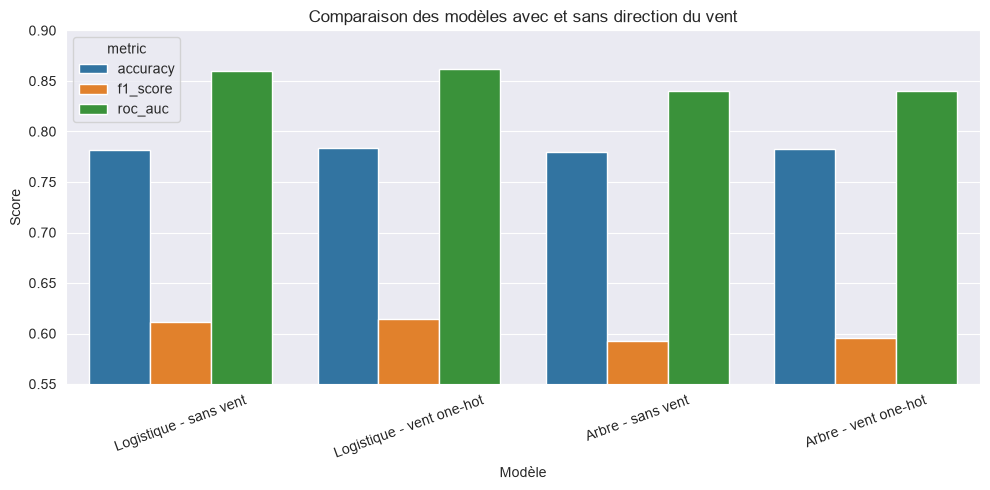

In [26]:
plot_df_models = results_models.melt(id_vars="modele", var_name="metric", value_name="score")

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_df_models, x="modele", y="score", hue="metric")
plt.title("Comparaison des modèles avec et sans direction du vent")
plt.xlabel("Modèle")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0.55, 0.90)
plt.tight_layout()
plt.savefig("figure_modeles_vent.png", dpi=300, bbox_inches="tight")
plt.show()

In [27]:
from sklearn.tree import DecisionTreeClassifier

On importe le modèle Decision Tree pour tester un modèle non linéaire.

In [28]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_proba_dt = dt.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("F1 score :", f1_score(y_test, y_pred_dt))
print("ROC AUC  :", roc_auc_score(y_test, y_proba_dt))

Accuracy : 0.776148969889065
F1 score : 0.5094324729655063
ROC AUC  : 0.6864346648253057


On entraîne un arbre de décision sans variables de vent et on observe qu'il performe nettement moins bien que la logistique, ce qui suggère une mauvaise capacité de généralisation.

In [ ]:
X_train_oh = pd.get_dummies(X_train_oh)
X_test_oh = pd.get_dummies(X_test_oh)

X_train_oh, X_test_oh = X_train_oh.align(X_test_oh, join='left', axis=1, fill_value=0)

On transforme les variables catégorielles du vent en variables numériques pour permettre à l’arbre de décision de les exploiter.

In [ ]:
dt_oh = DecisionTreeClassifier(random_state=42)

dt_oh.fit(X_train_oh, y_train_oh)

y_pred_dt_oh = dt_oh.predict(X_test_oh)
y_proba_dt_oh = dt_oh.predict_proba(X_test_oh)[:, 1]

print("Accuracy :", accuracy_score(y_test_oh, y_pred_dt_oh))
print("F1 score :", f1_score(y_test_oh, y_pred_dt_oh))
print("ROC AUC  :", roc_auc_score(y_test_oh, y_proba_dt_oh))

On ajoute les variables de direction du vent à l’arbre mais on observe un impact très limité, ce qui suggère que ce modèle exploite mal cette information.

In [ ]:
y_pred_train_dt = dt.predict(X_train)
y_proba_train_dt = dt.predict_proba(X_train)[:, 1]

print("TRAIN")
print("Accuracy :", accuracy_score(y_train, y_pred_train_dt))
print("F1 score :", f1_score(y_train, y_pred_train_dt))
print("ROC AUC  :", roc_auc_score(y_train, y_proba_train_dt))

Overfitting, generalise mal le train

In [ ]:
dt_reg = DecisionTreeClassifier(max_depth=5, random_state=42)

dt_reg.fit(X_train, y_train)

y_pred_dt_reg = dt_reg.predict(X_test)
y_proba_dt_reg = dt_reg.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_dt_reg))
print("F1 score :", f1_score(y_test, y_pred_dt_reg))
print("ROC AUC  :", roc_auc_score(y_test, y_proba_dt_reg))

On limite la profondeur de l’arbre pour réduire l'overfitting, ce qui améliore bien la ROC AUC mais le F1 ne bouge pas

In [ ]:
y_pred_train_dt_reg = dt_reg.predict(X_train)
y_proba_train_dt_reg = dt_reg.predict_proba(X_train)[:, 1]

print("TRAIN")
print("Accuracy :", accuracy_score(y_train, y_pred_train_dt_reg))
print("F1 score :", f1_score(y_train, y_pred_train_dt_reg))
print("ROC AUC  :", roc_auc_score(y_train, y_proba_train_dt_reg))

nLa régularisation permet d’obtenir un modèle stable avec des performances similaires entre train et test, on a bine réduction du surapprentissage

In [ ]:
importances = pd.Series(dt_reg.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False)

importances.head(10)

L’arbre de décision repose principalement sur l’humidité à 15h et ignore presque totalement les variables de vent

In [ ]:
results_compare = pd.DataFrame({
    "modele": [
        "Logistique",
        "Arbre régularisé"
    ],
    "accuracy": [
        accuracy_score(y_test_oh, y_pred_oh),
        accuracy_score(y_test, y_pred_dt_reg)
    ],
    "f1_score": [
        f1_score(y_test_oh, y_pred_oh),
        f1_score(y_test, y_pred_dt_reg)
    ],
    "roc_auc": [
        roc_auc_score(y_test_oh, y_proba_oh),
        roc_auc_score(y_test, y_proba_dt_reg)
    ]
})

results_compare

In [ ]:
results_compare = pd.DataFrame({
    "modele": [
        "Logistique",
        "Arbre régularisé"
    ],
    "accuracy": [
        0.783862,
        accuracy_score(y_test, y_pred_dt_reg)
    ],
    "f1_score": [
        0.605318,
        f1_score(y_test, y_pred_dt_reg)
    ],
    "roc_auc": [
        0.851406,
        roc_auc_score(y_test, y_proba_dt_reg)
    ]
})

results_compare

In [ ]:
plot_df_compare = results_compare.melt(id_vars="modele", var_name="metric", value_name="score")

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_df_compare, x="modele", y="score", hue="metric")
plt.title("Comparaison finale des modèles")
plt.ylim(0.5, 0.9)
plt.tight_layout()
plt.show()

logistique plus performante

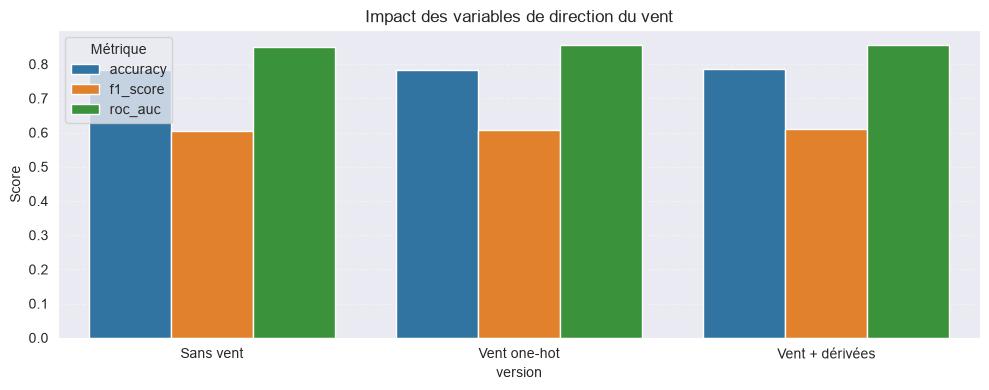

In [33]:
plt.figure(figsize=(10,4))

results_wind_full = pd.DataFrame({
    "version": [
        "Sans vent",
        "Vent one-hot",
        "Vent + dérivées"
    ],
    "accuracy": [
        0.783862,
        0.783720,
        0.784433
    ],
    "f1_score": [
        0.605318,
        0.607299,
        0.609207
    ],
    "roc_auc": [
        0.851406,
        0.854611,
        0.855663
    ]
})

plot_df = results_wind_full.melt(id_vars="version", var_name="metric", value_name="score")

sns.barplot(data=plot_df, x="version", y="score", hue="metric")

plt.title("Impact des variables de direction du vent")
plt.ylabel("Score")

plt.xticks(rotation=0)
plt.legend(title="Métrique", loc="upper left")

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

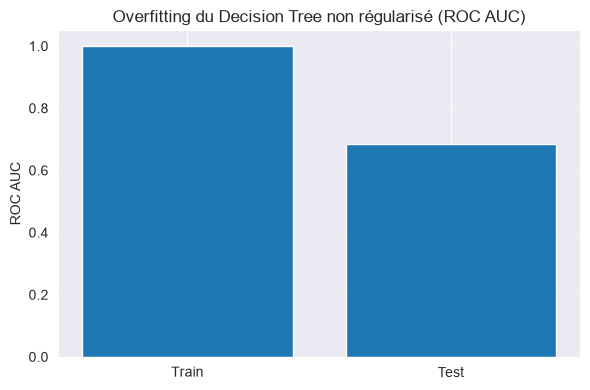

In [34]:
plt.figure(figsize=(6,4))

plt.bar(["Train", "Test"], [1.0, 0.686])

plt.title("Overfitting du Decision Tree non régularisé (ROC AUC)")
plt.ylabel("ROC AUC")

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

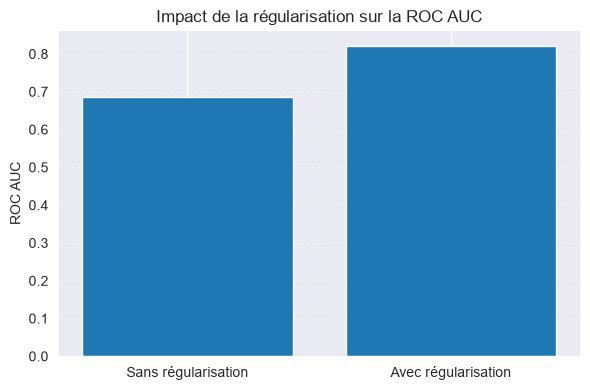

In [35]:
plt.figure(figsize=(6,4))

plt.bar(["Sans régularisation", "Avec régularisation"], [0.686, 0.821])

plt.title("Impact de la régularisation sur la ROC AUC")
plt.ylabel("ROC AUC")

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
from sklearn.tree import DecisionTreeClassifier

dt_reg = DecisionTreeClassifier(max_depth=5, random_state=42)

dt_reg.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

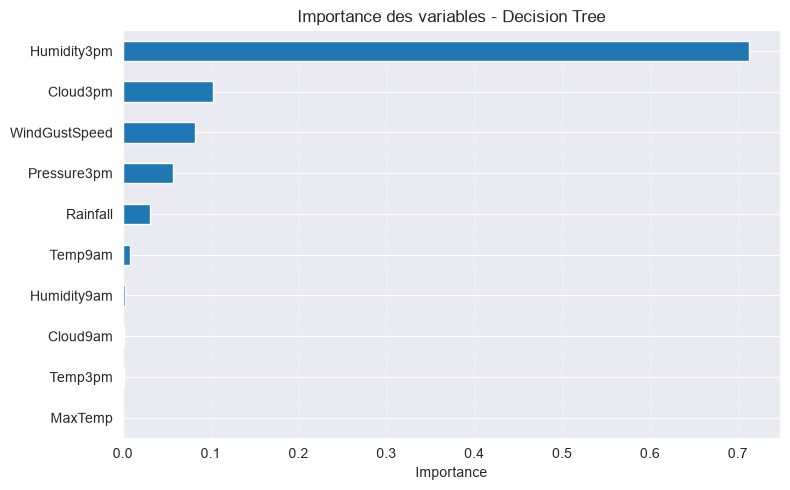

In [38]:
importances = pd.Series(dt_reg.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(8,5))

importances.head(10).plot(kind="barh")

plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Importance des variables - Decision Tree")

plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [40]:
y_pred_dt_reg = dt_reg.predict(X_test)
y_proba_dt_reg = dt_reg.predict_proba(X_test)[:, 1]

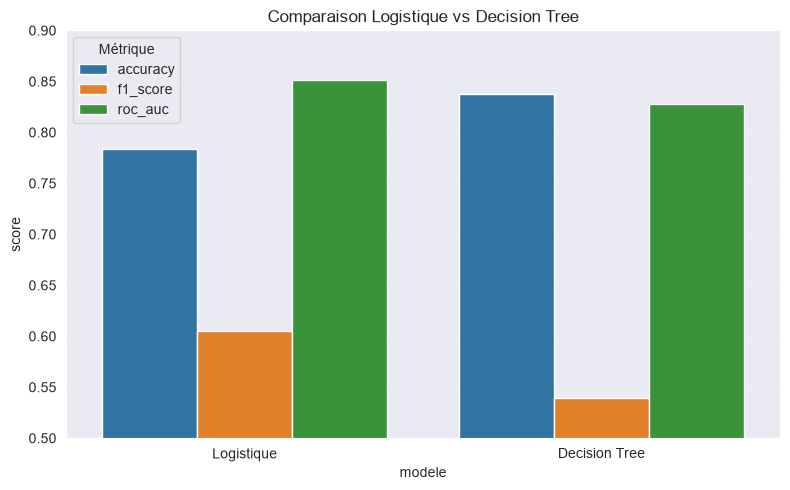

In [41]:
results_compare = pd.DataFrame({
    "modele": [
        "Logistique",
        "Decision Tree"
    ],
    "accuracy": [
        0.783862,
        accuracy_score(y_test, y_pred_dt_reg)
    ],
    "f1_score": [
        0.605318,
        f1_score(y_test, y_pred_dt_reg)
    ],
    "roc_auc": [
        0.851406,
        roc_auc_score(y_test, y_proba_dt_reg)
    ]
})

plot_df = results_compare.melt(id_vars="modele", var_name="metric", value_name="score")

plt.figure(figsize=(8,5))

sns.barplot(data=plot_df, x="modele", y="score", hue="metric")

plt.title("Comparaison Logistique vs Decision Tree")
plt.ylim(0.5, 0.9)

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.legend(title="Métrique")

plt.tight_layout()
plt.show()